# Topic Modeling
### Bert Sentence Embedding, LDA, and K-means Clustering

#### Concatenate the sentence embeddings with LDA, use an autoencoder to get the latent representation and perform K-means to perform clustering on the data

#### After the sentences have been assigned to their clusters, we can extract the candidate topics for each cluster using tokens of it's sentences

In [1]:
from google.colab import drive
drive.mount('/content/drive/')


Go to this URL in a browser: https://accounts.google.com/o/oauth2/auth?client_id=947318989803-6bn6qk8qdgf4n4g3pfee6491hc0brc4i.apps.googleusercontent.com&redirect_uri=urn%3aietf%3awg%3aoauth%3a2.0%3aoob&scope=email%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdocs.test%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdrive%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdrive.photos.readonly%20https%3a%2f%2fwww.googleapis.com%2fauth%2fpeopleapi.readonly&response_type=code

Enter your authorization code:
··········
Mounted at /content/drive/


In [40]:
% cd /content/drive/My Drive/Thesis_colab

/content/drive/My Drive/Thesis_colab


In [3]:
! pip install transformers
! pip install pandas
! pip install torch
! pip install nltk
! pip install gensim
! pip install matplotlib
! pip install umap-learn
! pip install wordcloud
! pip install sklearn
! pip install tqdm
! pip install stop_words
! pip install xlrd
! pip install langdetect
! pip install openpyxl

     |████████████████████████████████| 778kB 2.8MB/s 
     |████████████████████████████████| 1.1MB 16.7MB/s 
     |████████████████████████████████| 890kB 19.8MB/s 
     |████████████████████████████████| 3.0MB 23.9MB/s 
  Created wheel for sacremoses: filename=sacremoses-0.0.43-cp36-none-any.whl size=893260 sha256=38b3c775e9b745e1507d2f3676e6ca3575097778ce855f05855c067b0fc5e7bd
  Stored in directory: /root/.cache/pip/wheels/29/3c/fd/7ce5c3f0666dab31a50123635e6fb5e19ceb42ce38d4e58f45
Successfully built sacremoses
  Created wheel for stop-words: filename=stop_words-2018.7.23-cp36-none-any.whl size=32917 sha256=597e3ed75104b72cd223dc96781d08e046c931edf914bc2fc7fa6924996f2cb8
  Stored in directory: /root/.cache/pip/wheels/75/37/6a/2b295e03bd07290f0da95c3adb9a74ba95fbc333aa8b0c7c78
Successfully built stop-words
     |████████████████████████████████| 983kB 2.8MB/s 
  Created wheel for langdetect: filename=langdetect-1.0.8-cp36-none-any.whl size=993193 sha256=4ce957ad330559b9495b58e49be10

In [25]:
import nltk
import numpy as np
import statistics
from sklearn.decomposition import PCA
from collections import Counter

In [5]:
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.


True

### 1. Reading and preprocessing the data

In [ ]:
from utilities.document_preprocessing import preprocess_documents

#### The preprocess_document function reads the sentences from the file and generates tokens from each sentences.

In [11]:
Verbose = False

In [ ]:
# Read new data file
file = "data/PMP_Skills_Matching_Pilot_2018_2019_small.xlsx"

ids, sentences, token_lists = preprocess_documents(file, verbose = Verbose)
num_docs = len(ids)

In [6]:
#read the previously processed data
import pandas as pd
data = pd.read_pickle("output/preprocessed_data/use_this_data.pkl")
sentences = list(data['sentences'])
token_lists = list(data['token_list'])
ids = list(data['id'])
num_docs = len(ids)

In [7]:
len(ids)

78969

## 2. Topic Modeling

In [8]:
from models.topic_model import Topic_Model

#### The topic_Model class does the follow
- Extract Bert sentence embeddings for all sentences (Local features)
- get topic distribution for each sentence using LDA
- concatenate both and learn the latent representation using an auto-encoder
- cluster the latent representation into K clusters

In [9]:
# define the numbe of clusters
k = 5

In [143]:
# Define the topic model object
TopicModelObject = Topic_Model(k = k, verbose = Verbose, embedding = None, 
                               saved_embedding_dir = "output/preprocessed_data/bert_embeddings.json", embedding_batch_size = 100)

In [12]:
# for Colab
# Define the topic model object
TopicModelObject = Topic_Model(k = k, verbose = Verbose, embedding = 'bert', 
                               saved_embedding_dir = "output/embeddings/2020_06_29_20_24_15_bert/bert_embeddings.json", embedding_batch_size = 100)

In [144]:
# Fit the topic model
TopicModelObject.fit(sentences, token_lists)

Getting vector representations for LDA 
Getting vector representations for LDA. Done! 

 LDA Done.


## 3. Analysis on learned features

#### Preprocessing (Dimensionality Reduction) for visualization

Perform Dimensionality reduction on the learned features using the following steps:

1) Merge all the vectors of each employee into one by taking average

2) Assign the class label to each employee based on argmax on label counts.

3) Further compress the average feature vector into 2d/3d space for visualization.

In [145]:
# Getting feature vectors and cluster labels assigned by the model
if TopicModelObject.method == 'LDA':
    feature_vector = TopicModelObject.vec[TopicModelObject.method]
    # for each sentence, find out the cluster it belongs to
    cluster_label_per_document = np.argmax(np.array(feature_vector), axis=1)
else:
    cluster_label_per_document = np.array(TopicModelObject.cluster_model.labels_)
    feature_vector = TopicModelObject.vec[TopicModelObject.method]
    feature_vector = feature_vector.cpu().numpy()

unique_ids = list(set(ids))
num_employee = len(unique_ids)

In [19]:
# Create place holder for the analysis
averaged_employee_features = pd.DataFrame(None, index=pd.Index(unique_ids, name='Employee id'),
                                          columns=pd.Index(
                                              ['feature_vector', 'cluster', 'feature_vector_2d', 'feature_vector_3d'],
                                              name='Compressed_features'))

In [20]:
# get the indices of all objectives/documents/sentence for each employee (for later use)
employee_objective_indices = dict()
for employee in unique_ids:
    employee_indices = [i for i, e in enumerate(ids) if (ids[i] == employee) ]
    employee_objective_indices[employee] = employee_indices

In [36]:
# 1 & 2 take average of all feature vectors belonging to an employee and assigning cluster label by taking the mode

for employee in unique_ids:
    #get all feature vectors belonging to an employee
    feature_vector_per_employee = feature_vector[employee_objective_indices[employee]]
    # get label for all feature vectors belonging to that employee
    clusters_per_employee = cluster_label_per_document[employee_objective_indices[employee]]  
    
    #take mean of all feature vectors
    averaged_employee_features['feature_vector'][employee] = np.mean(feature_vector_per_employee, axis=0)
    
    # pick the label with most occurance for that employee
    c = Counter(clusters_per_employee)
    averaged_employee_features['cluster'][employee] = c.most_common(1)[0][0]
    
averaged_employee_features

Compressed_features,feature_vector,cluster,feature_vector_2d,feature_vector_3d
Employee id,,,,
*100347,"[0.5690834, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",2,NaN,NaN
*100418,"[0.41545758, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...",2,NaN,NaN
*100382,"[0.36821064, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...",2,NaN,NaN
*100461,"[0.2778129, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",2,NaN,NaN
*100324,"[1.3299668, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",2,NaN,NaN
...,...,...,...,...
*100092,"[1.2254074, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",2,NaN,NaN
*100255,"[0.18200183, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...",4,NaN,NaN
*100398,"[0.34710962, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...",3,NaN,NaN


In [37]:
# 3) doing dimensionality reduction into 2d/3d Space
from sklearn.manifold import TSNE

#todo: find a more permanent solution for this
# panda returns a array of array for the column feature vector. Converting from array of array to 2d array
feature_vector_ = np.stack(averaged_employee_features['feature_vector'].to_numpy())

# reduce dimension of feature vectors into 2
feature_vector_2d = TSNE(n_components=2).fit_transform(feature_vector_)
averaged_employee_features['feature_vector_2d'] = list(feature_vector_2d)

# reduce dimension of feature vectors into 3
feature_vector_3d = TSNE(n_components=3).fit_transform(feature_vector_)
averaged_employee_features['feature_vector_3d'] = list(feature_vector_3d)


averaged_employee_features

Compressed_features,feature_vector,cluster,feature_vector_2d,feature_vector_3d
Employee id,,,,
*100347,"[0.5690834, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",2,"[-18.848536, 0.214549]","[25.826134, -20.060596, 64.78136]"
*100418,"[0.41545758, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...",2,"[-7.6684594, 10.1265955]","[3.6822867, -41.91703, 9.6068735]"
*100382,"[0.36821064, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...",2,"[3.2493875, 3.864868]","[13.977505, -9.283041, -27.531227]"
*100461,"[0.2778129, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",2,"[-9.022045, 2.6980224]","[10.779245, -84.65372, -26.06737]"
*100324,"[1.3299668, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",2,"[-13.015873, 8.208118]","[35.98889, -103.459656, 28.182695]"
...,...,...,...,...
*100092,"[1.2254074, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",2,"[-6.695336, 2.1192343]","[13.707444, -58.247433, -24.52532]"
*100255,"[0.18200183, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...",4,"[10.819378, -2.5218117]","[-32.639606, 16.88182, -21.392105]"
*100398,"[0.34710962, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...",3,"[4.4392943, -23.361176]","[-42.92384, -85.11129, -27.76176]"


## 4.1 Visualization: Word Cloud

In [41]:
from utilities.visualizations import get_wordcloud
from utilities.utils import generate_n_gram
%matplotlib inline

In [42]:
#Getting indexes of sentences belonging to each cluster
sentence_label_dict = dict()
for label in set(TopicModelObject.cluster_model.labels_):
    sentence_label_dict[label] = [idx for idx, l in enumerate(TopicModelObject.cluster_model.labels_) if l == label]

WordClouds for 1 grams
Getting wordcloud for topic 0 ...
Getting wordcloud for topic 0. Done!
Getting wordcloud for topic 1 ...
Getting wordcloud for topic 1. Done!
Getting wordcloud for topic 2 ...
Getting wordcloud for topic 2. Done!
Getting wordcloud for topic 3 ...
Getting wordcloud for topic 3. Done!
Getting wordcloud for topic 4 ...
Getting wordcloud for topic 4. Done!


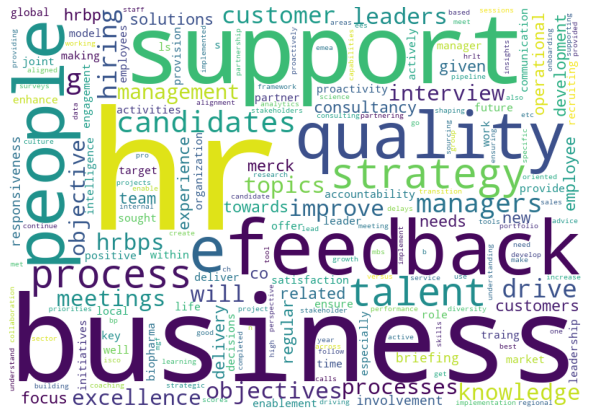

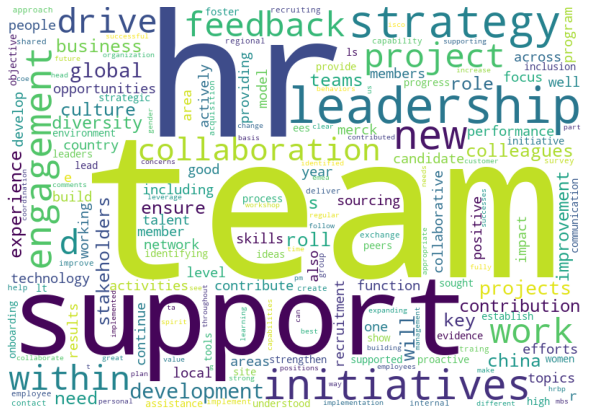

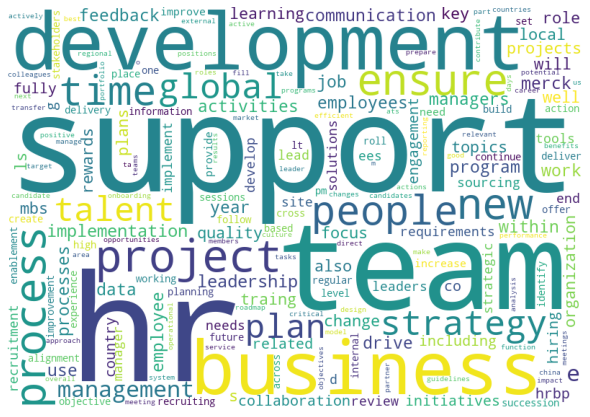

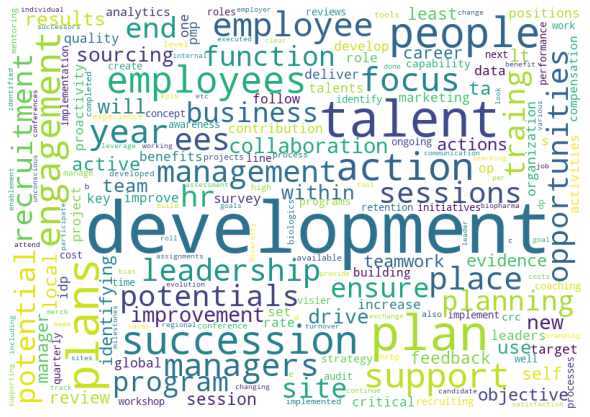

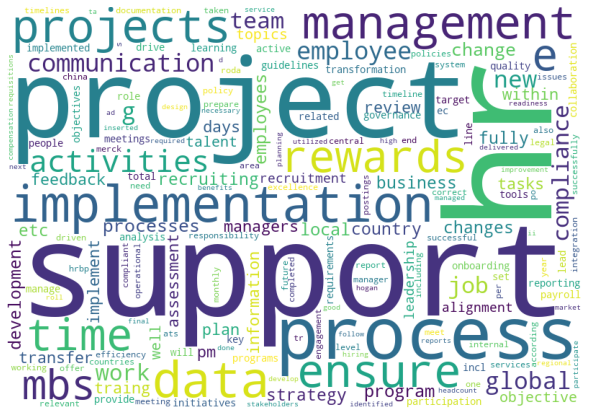

In [43]:
### Top words from LDA
if TopicModelObject.method == 'LDA':
    
    lda_class_distribution = TopicModelObject.vec["LDA"]
    labels = np.argmax(lda_class_distribution, axis=1)
    print (labels.shape)

    # To get the top words for each topic, this method only uses LDA, doesn't utilize Bert or K mean clustering
    TopicModelObject.get_top_words_lda(top=10)

    for k , cluster_word_distribution in TopicModelObject.get_top_words_lda(top=100).items():
        get_wordcloud(TopicModelObject, word_distribution = cluster_word_distribution, topic = k )
# Get top words from autoencoder (LDA + Embeddings) and create word clouds on n grams
else:
    grams = 1
    for ng in range(grams):
        print ("WordClouds for {} grams".format(str(ng+1)))
        for i in range(TopicModelObject.k):

            k_sentences = np.array(sentences)[sentence_label_dict[i]]
            ngram_token_with_frequency = generate_n_gram(k_sentences, n=ng+1, separator = '-' ,
                                        keep_stopwords= False, stem=False, keep_nouns_only=False)
    
            get_wordcloud(TopicModelObject, topic=i, word_count_dict = ngram_token_with_frequency)
    

## 4.2 Visualization: Scatter plot

Visualize the feature vectors of each employee in a 2d/3d space using plotly

In [44]:
import plotly.graph_objects as go

In [45]:
from collections import Counter
#main topics for each cluster
cluster_titles = []

for i in range(TopicModelObject.k):
    k_sentences = np.array(sentences)[sentence_label_dict[i]]
    ngram_token_with_frequency = Counter(generate_n_gram(k_sentences, n=3, separator = '-' ,
                                        keep_stopwords= True, stem=False, keep_nouns_only=False))
    
    
    cluster_title = ', '.join([key for key, value in ngram_token_with_frequency.most_common(6)])
    
    cluster_titles.append(cluster_title)
cluster_titles

['of-the-business, on-quality-of, feedback-will-be, knowledge-of-the, hiring-managers-and, will-be-sought',
 'roll-out-of, contribution-to-the, the-roll-out, within-the-team, d-i-initiatives, out-of-global',
 'as-well-as, time-to-fill, time-to-offer, and-time-to, to-fill-and, fill-and-time',
 'collaboration-and-teamwork, opportunities-for-improvement, identifying-opportunities-for, in-identifying-opportunities, on-self-development, focus-on-self',
 'and-process-compliance, recruitment-tools-and, tools-and-process, efficiency-and-process, recruiting-efficiency-and, area-of-responsibility']

In [142]:
fig = go.Figure()


for i, cl in enumerate(range(k)):
    cluster_df = averaged_employee_features[averaged_employee_features.cluster==cl]
    #plot all the employees belonging to a cluster using a new trace. 
    features = np.stack(cluster_df['feature_vector_2d'].to_numpy())


    fig.add_trace(go.Scattergl(
      x=features[:, 0],
      y=features[:, 1],
      mode='markers',
      showlegend=True,
      text = cluster_df.index.values,
      marker=dict(size=8, color=i),
      name="cluster_"+str(cl+1) +": " + cluster_titles[cl]
  ))



fig.update_layout(title='Distribution of employees over clusters in 2d space', legend=dict(
        x=0.6,
        y=1.4,
        traceorder='normal',
        font=dict(
            size=10)))
fig.show()


In [56]:
fig = go.Figure()


for i, cl in enumerate(range(k)):
    cluster_df = averaged_employee_features[averaged_employee_features.cluster==cl]

    #plot all the employees belonging to a cluster using a new trace. 
    features = np.stack(cluster_df['feature_vector_2d'].to_numpy())
    #normalize the features between 0 and 1
    
    print ("\n data \n ",features)
    min_ = features.min(axis=0)
    max_ = features.max(axis=0)
    print ("Row wise minimum: ", features.min(axis=0))
    print ("Row wise maximum: ", features.max(axis=0))
    features_normed = (features - min_ )/ (max_ - min_) 
    
    print ("Normalized\n", features_normed)


    fig.add_trace(go.Scattergl(
      x=features_normed[:, 0],
      y=features_normed[:, 1],
      mode='markers',
      showlegend=True,
      text = cluster_df.index.values,
      marker=dict(size=8, color=i),
      name="cluster_"+str(cl+1) +": " + cluster_titles[cl]
    ))



fig.update_layout(title='Distribution of employees over clusters in 2d space - Normalized', legend=dict(
        x=0.6,
        y=1.4,
        traceorder='normal',
        font=dict(
            size=10)))
fig.show()


 data 
  [[ -4.536635   -15.132359  ]
 [ 12.186522   -11.480535  ]
 [  1.6483083  -12.874743  ]
 [ -5.559166    -7.3054266 ]
 [ 12.089381   -13.018019  ]
 [ 11.937642    -7.7467513 ]
 [ 12.663571   -10.071996  ]
 [ -7.8140388  -12.794261  ]
 [ 12.491125   -13.38994   ]
 [  1.486743   -13.525223  ]
 [  8.373289   -11.983394  ]
 [ -3.1815727  -17.832502  ]
 [ -8.910306   -14.636558  ]
 [-11.041135    -9.190551  ]
 [ 13.687657   -10.622921  ]
 [ -6.5971994  -13.887581  ]
 [  1.4716073    4.4137816 ]
 [  6.3278093   -7.915363  ]
 [ 11.639289   -13.758608  ]
 [  1.522969   -11.724455  ]
 [ 15.57024    -10.225281  ]
 [-10.9012575  -10.019833  ]
 [ 11.202828    -9.702676  ]
 [ -1.0893503  -12.443415  ]
 [  9.91479    -10.035376  ]
 [-15.770714    22.73276   ]
 [ 18.570662    -8.662013  ]
 [ -6.3603096  -14.344156  ]
 [ 12.865307    -7.687349  ]
 [ 13.326727    -9.465608  ]
 [-15.420609   -10.8431225 ]
 [ -3.1753633  -16.25614   ]
 [ -1.3391953  -10.828684  ]
 [ 10.748436   -10.753846  ]
 [ -

In [59]:
fig = go.Figure()

for i , cl in enumerate(range(k)):
    cluster_df = averaged_employee_features[averaged_employee_features.cluster==cl]

    #plot all the employees belonging to a cluster using a new trace. 
    features = np.stack(cluster_df['feature_vector_3d'].to_numpy())

    fig.add_trace(go.Scatter3d(
      x=features[:, 0],
      y=features[:, 1],
      z=features[:, 2],
      mode='markers',
      showlegend=True,
      text = cluster_df.index.values,
      marker=dict(size=3, color=i),
      name="cluster_"+str(cl+1) +": " + cluster_titles[cl]
    ))

fig.update_layout(title='Distribution of employees over clusters in 3d Space', legend=dict(
        x=0.6,
        y=1.4,
        traceorder='normal',
        font=dict(
            size=10)))
fig.show()

In [61]:
fig = go.Figure()

for i, cl in enumerate(range(k)):
    cluster_df = averaged_employee_features[averaged_employee_features.cluster==cl]

    #plot all the employees belonging to a cluster using a new trace. 
    features = np.stack(cluster_df['feature_vector_3d'].to_numpy())
    
    print ("\n data \n ",features)
    min_ = features.min(axis=0)
    max_ = features.max(axis=0)
    print ("Row wise minimum: ", features.min(axis=0))
    print ("Row wise maximum: ", features.max(axis=0))
    features_normed = (features - min_ )/ (max_ - min_) 
    
    print ("Normalized\n", features_normed)

    fig.add_trace(go.Scatter3d(
      x=features_normed[:, 0],
      y=features_normed[:, 1],
      z=features_normed[:, 2],
      mode='markers',
      showlegend=True,
      text = cluster_df.index.values,
      marker=dict(size=3, color=i),
      name="cluster_"+str(cl+1) +": " + cluster_titles[cl]
    ))

fig.update_layout(title='Distribution of employees over clusters in 3d Space - Normalized', legend=dict(
        x=0.6,
        y=1.4,
        traceorder='normal',
        font=dict(
            size=10)))
fig.show()


 data 
  [[  11.496936    36.003963    41.284954 ]
 [ -80.85251     -4.0625587   26.673252 ]
 [ -21.774317    58.774906    38.136723 ]
 [  10.007059    48.651104     3.3479755]
 [ -63.46001     71.95394    -46.27042  ]
 [ -48.56371     17.506302     2.0200956]
 [ -72.17011     11.772333    19.934586 ]
 [   3.9371412   -4.360029    29.585321 ]
 [ -57.54249     83.96194    -51.33214  ]
 [  -9.75752     66.412415    39.667267 ]
 [ -43.236534    53.53152     10.14043  ]
 [ -56.817356   -13.393886    56.1718   ]
 [  -5.7171264  -18.08422     34.766617 ]
 [ -45.725166   -43.21815     24.217854 ]
 [ -84.671326    10.112398    11.831424 ]
 [  -5.7012525    9.890629    52.377693 ]
 [ -67.140305   -28.563301    33.28261  ]
 [  -5.6163344   33.363693     9.848768 ]
 [ -50.76205     76.222015   -40.19751  ]
 [ -20.811533    68.96209     54.811203 ]
 [ -99.06607     19.99846      8.798979 ]
 [  45.089497    61.04863    -53.81065  ]
 [ -61.89474      1.8214791   10.517808 ]
 [  -9.94384     46.6019

## 4.3 Visualization (Network)

In [ ]:
from pyvis.network import Network
import networkx as nx

In [ ]:
#create a dataframe to store the frequence per cluster for each employee. 
df_id_cluster = pd.DataFrame(0,
                  index=pd.Index(unique_ids, name='Employee id'),
                  columns=pd.Index([i for i in range(k)], name='Clusters'))
#There are multiple entries per employee so an employee can belong to multiple clusters
for i, _id in enumerate(ids):
    df_id_cluster[cluster_label_per_document[i]][_id] += 1
    
employee_cluster_frequency = df_id_cluster.values.tolist()
employee_cluster_frequency

[[6, 30], [108, 54], [7, 0]]

In [ ]:
net = Network("500px", "500px")

In [ ]:
# Create all cluster nodes

#cluster ids
cluster_node_ids = ["cluster_" + str(i+1) for i in range(k)]

#size of the cluster nodes
cluster_node_size = 1000

cluster_sizes = [cluster_node_size for _ in range(k)]
x = [40+i for i in range(k)]
y = [40+i for i in range(k)]
color = ["#dd4b39" for i in range(k)]

#main topics for each cluster
cluster_titles = []
for key, value in TopicModelObject.get_top_words_lda(top=10).items():
    cluster_title = ', '.join([item[0] for item in value])
    cluster_titles.append(cluster_title)

print(cluster_titles)


net.add_nodes(cluster_node_ids, value= cluster_sizes, 
              title=cluster_titles, 
              x=x, y=y, 
              label=cluster_node_ids, 
              color=color)


['cluster_1', 'cluster_2']
['support, leadership, busi, team, job, post, roll, ta, qualiti, candid', 'employe, biolog, initi, support, talent, develop, appropri, drive, project, plan']


In [ ]:
# create all employee nodes

#employee ids
employee_node_ids = list(set(ids))

#size of the employee nodes
employee_node_size = 200

employee_node_sizes = [employee_node_size for _ in range(len(employee_node_ids))]
x = [10+i for i in range(len(employee_node_ids))]
y = [40+i for i in range(len(employee_node_ids))]
color = ["#162347" for i in range(len(employee_node_ids))]
 



# get all objective indices for each employee
employee_objective_indices = dict()
for employee in employee_node_ids:
    employee_indices = [i for i, e in enumerate(ids) if (ids[i] == employee) ]
    employee_objective_indices[employee] = employee_indices
    

#All objectives belong to an employee are concatenated
employee_titles = []
np_sentences = np.array(sentences)
for key, value in employee_objective_indices.items():
    employee_title = '. '.join([objective for objective in np_sentences[value]])
    
    employee_titles.append(employee_title)

subset= 3   

net.add_nodes(employee_node_ids[:subset], value=employee_node_sizes[:subset], 
              title=employee_titles[:subset], 
              x=x[:subset], y=y[:subset], 
              label=employee_node_ids[:subset], 
              color=color[:subset])

In [ ]:
# create all edges between employees and clusters
for emp,employee_cluster in enumerate(employee_cluster_frequency):
    for cl, cluster in enumerate(employee_cluster):
        
        # If the employee belongs to that cluster
        if cluster > 0:
            
            #print (employee_node_ids[emp],cluster_node_ids[cl])
            net.add_edge(employee_node_ids[emp],cluster_node_ids[cl],weight=float(cluster/num_docs))
            

In [ ]:
net.show_buttons(filter_=['physics'])

In [ ]:
# visualize the network
net.show("example.html")